# Physics 3926F — Lecture 5b Notebook

In [1]:
import numpy as np
import numpy.linalg as np_linalg
import matplotlib.pyplot as plt

## 1. Euler's method: the slide example, run longer
Slide example: $k = m = 1$, $x_0 = 1$, $v_0 = 0$, so
$$\frac{dx}{dt} = v,\qquad \frac{dv}{dt} = -x, \qquad \text{exact solution: } x(t) = \cos t$$

First, the two steps from the slide ($\tau = 0.1$), with the same code as slide 6.

In [2]:
def f(t, y):
    x, v = y                     # unpack the state
    return np.array([v, -x])     # [dx/dt, dv/dt]  (k = m = 1)

tau = 0.1
y = np.array([1.0, 0.0])         # state y = [x0, v0]
for n in range(2):
    y = y + tau * f(n*tau, y)    # both updates at once
    print(y)

[ 1.  -0.1]
[ 0.99 -0.2 ]


Same numbers as the slide: $(x_1, v_1) = (1, -0.1)$ and $(x_2, v_2) = (0.99, -0.2)$.

Now put the loop in a function so we can run it for any final time and any $\tau$.
It stores every step: one row per time, one column per state component ($x$, $v$).

In [3]:
def euler(f, y0, tf, tau):
    t = np.arange(0, tf + tau/2, tau)      # times 0, tau, 2 tau, ..., tf
    y = np.zeros((len(t), len(y0)))        # row n = state at time t[n]
    y[0] = y0
    for n in range(len(t) - 1):
        y[n+1] = y[n] + tau * f(t[n], y[n])
    return t, y

t, y = euler(f, [1.0, 0.0], 20, 0.1)
print("first 10 rows (x, v):\n", y[:10])      # same as above

first 10 rows (x, v):
 [[ 1.          0.        ]
 [ 1.         -0.1       ]
 [ 0.99       -0.2       ]
 [ 0.97       -0.299     ]
 [ 0.9401     -0.396     ]
 [ 0.9005     -0.49001   ]
 [ 0.851499   -0.58006   ]
 [ 0.793493   -0.6652099 ]
 [ 0.72697201 -0.7445592 ]
 [ 0.65251609 -0.8172564 ]]


### Run longer: $\tau = 0.1$ up to $t = 20$
**Predict first:** the exact $x(t) = \cos t$ keeps oscillating between −1 and 1. What will Euler do?

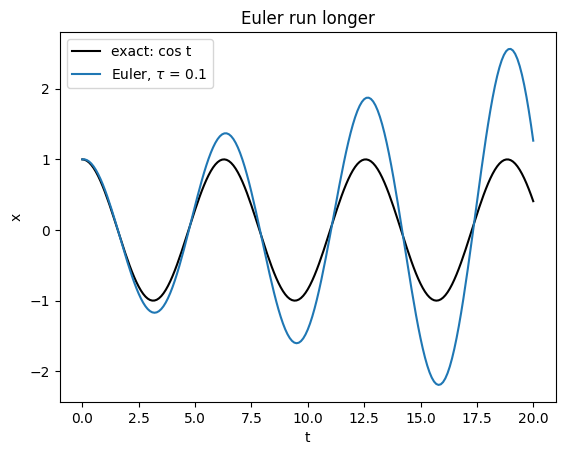

In [4]:
t, y = euler(f, [1.0, 0.0], 20, 0.1)

plt.plot(t, np.cos(t), "k", label="exact: cos t")
plt.plot(t, y[:, 0], label=r"Euler, $\tau$ = 0.1")
plt.xlabel("t"); plt.ylabel("x"); plt.legend()
plt.title("Euler run longer")
plt.show()

The first steps look fine, but the amplitude **grows** over time. The mass gains energy it shouldn't have:
each Euler step makes a small error, and here the errors build up instead of cancelling.

### Change $\tau$
**Predict first:** what happens if we make $\tau$ smaller?

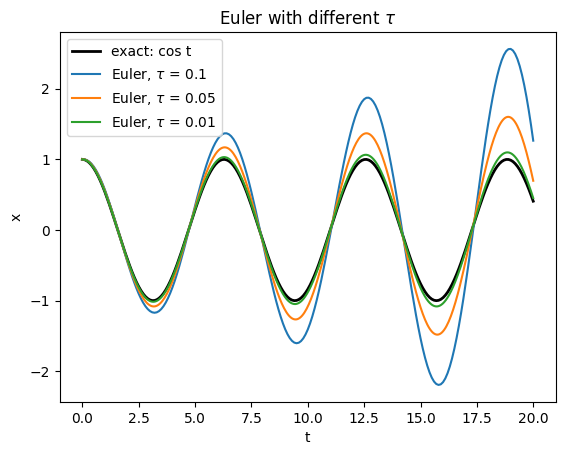

In [5]:
plt.plot(t, np.cos(t), "k", lw=2, label="exact: cos t")
for tau in [0.1, 0.05, 0.01]:
    t_e, y_e = euler(f, [1.0, 0.0], 20, tau)
    plt.plot(t_e, y_e[:, 0], label=rf"Euler, $\tau$ = {tau}")
plt.xlabel("t"); plt.ylabel("x"); plt.legend()
plt.title(r"Euler with different $\tau$")
plt.show()

Smaller $\tau$ stays closer to the exact solution, but costs more steps. How much closer? Measure the error at $t = 20$:

In [8]:
print(f"{'tau':>6} {'steps':>7} {'error in x at t = 20':>22}")
for tau in [0.1, 0.05, 0.01, 0.001]:
    t_e, y_e = euler(f, [1.0, 0.0], 20, tau)
    err = abs(y_e[-1, 0] - np.cos(t_e[-1]))
    print(f"{tau:>6} {len(t_e) - 1:>7} {err:>22.2e}")

   tau   steps   error in x at t = 20
   0.1     200               8.57e-01
  0.05     400               2.89e-01
  0.01    2000               4.36e-02
 0.001   20000               4.11e-03
